Student data shape: (5000, 20)
Topic data shape: (40000, 7)
  student_id   age grade_level  previous_marks  attendance_pct  \
0   STU04711  24.0      year 3            61.7           100.0   
1   STU00692  17.0      year 4            45.4            78.7   
2   STU00066  17.0      year 4            65.0            69.7   
3   STU03427  17.0      year 2            52.2            93.2   
4   STU04821  23.0      year 2            71.5            80.8   

   study_hours_per_week  study_days_per_week  study_consistency_pct  \
0                   1.9                    2                   73.1   
1                   0.1                    1                   65.2   
2                   1.7                    1                   88.3   
3                  11.8                    3                   78.4   
4                   7.7                    3                   97.1   

   sleep_hours_per_night  quiz_average  assignment_average  \
0                    6.6          68.5                

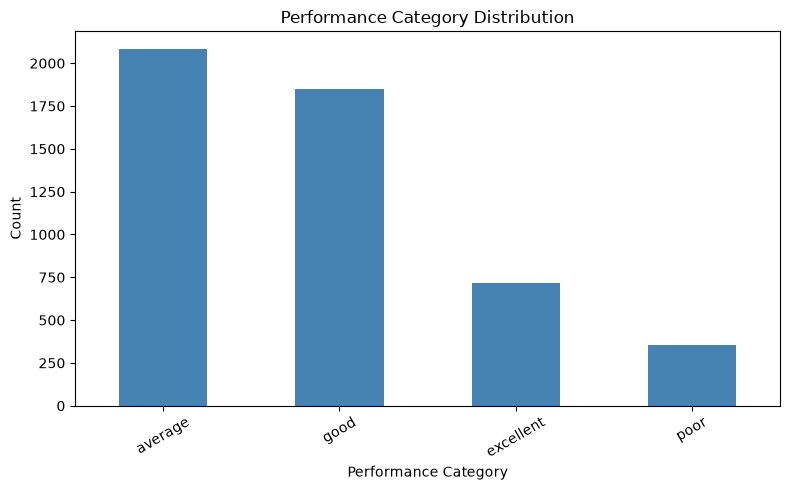

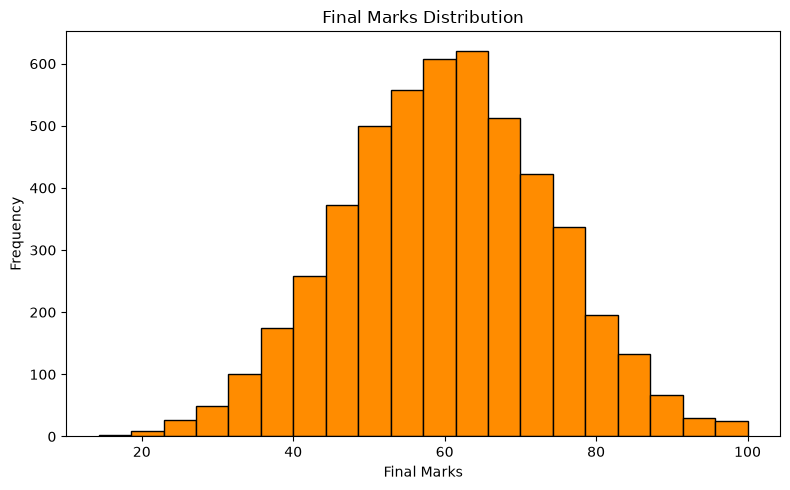

/tmp/ipykernel_2698/3206853176.py:169: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=student_df, x="performance_category", y="final_marks", palette="Set2")


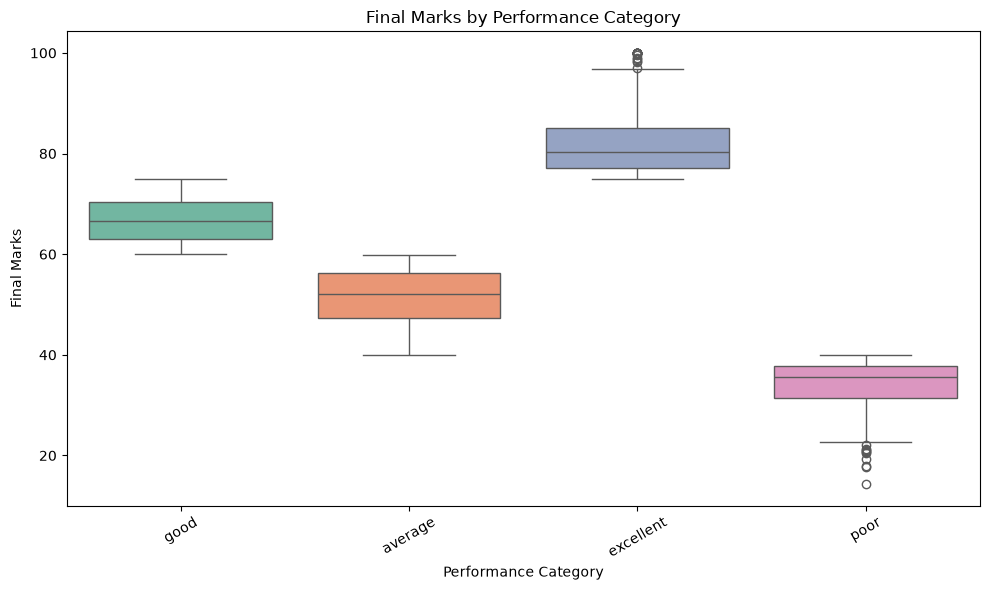

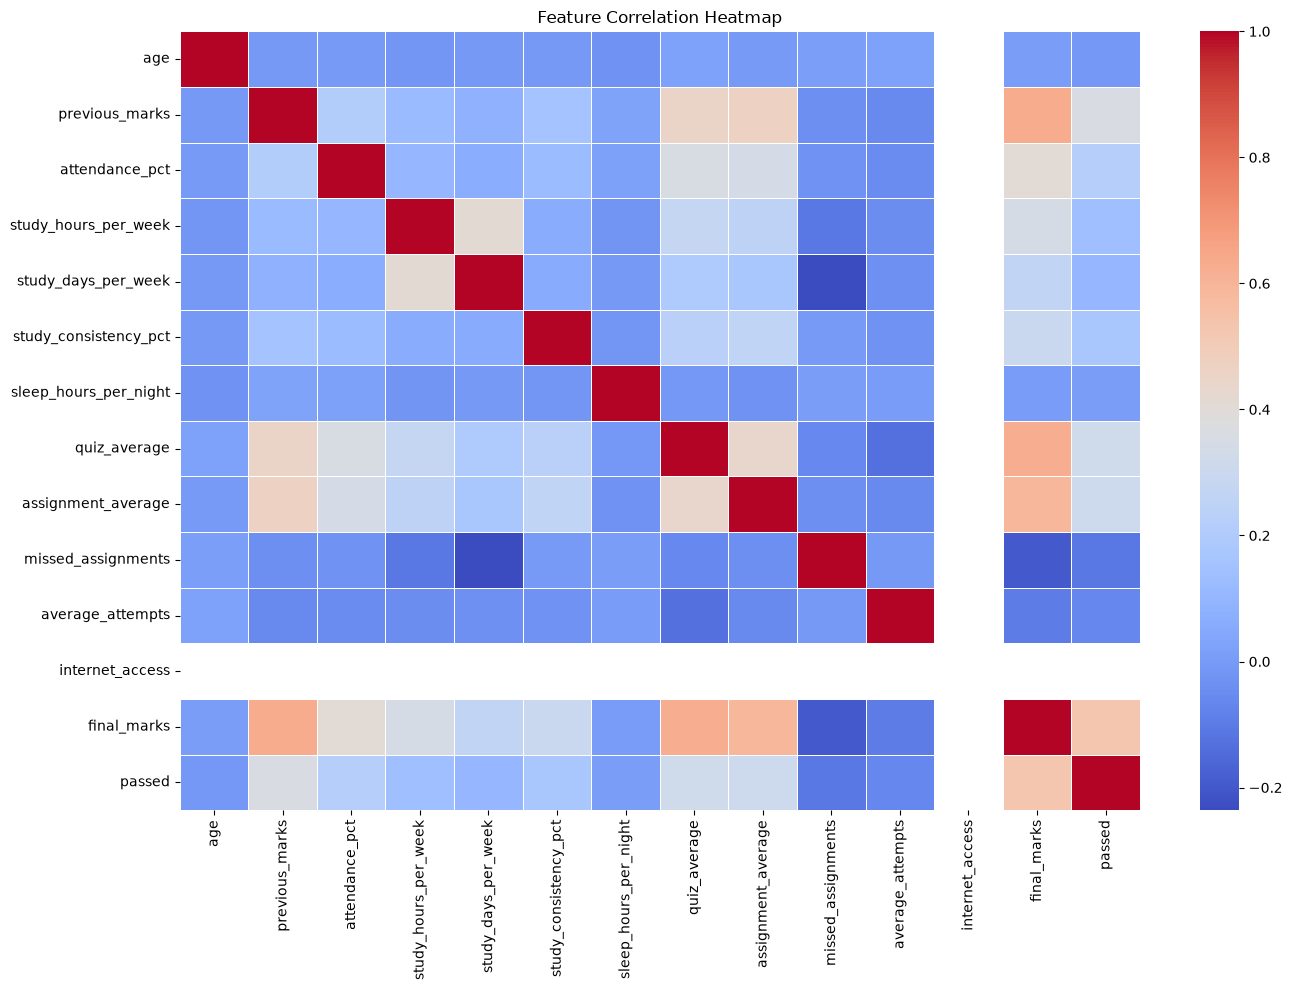


Model accuracy: 0.991
              precision    recall  f1-score   support

     average       0.99      1.00      0.99       417
   excellent       0.99      0.99      0.99       143
        good       0.99      0.98      0.99       369
        poor       1.00      0.99      0.99        71

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



In [1]:
# Import required libraries
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Project configuration
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "Notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

student_path = RAW_DIR / "student_performance_messy (1).csv"
topic_path = RAW_DIR / "topic_attempts_messy (1).csv"

# Read raw data
student_df = pd.read_csv(student_path)
topic_df = pd.read_csv(topic_path)

# Normalize column names
for df in (student_df, topic_df):
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)


def clean_student_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy().drop_duplicates().reset_index(drop=True)
    df["student_id"] = df["student_id"].astype(str).str.strip()

    for col in df.columns:
        if col == "student_id":
            continue
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], errors="coerce")
        else:
            df[col] = df[col].astype(str).str.strip().str.lower().replace({
                "nan": np.nan,
                "none": np.nan,
                "n/a": np.nan,
                "na": np.nan,
            })

    numeric_cols = [
        "age",
        "previous_marks",
        "attendance_pct",
        "study_hours_per_week",
        "study_days_per_week",
        "study_consistency_pct",
        "sleep_hours_per_night",
        "quiz_average",
        "assignment_average",
        "missed_assignments",
        "average_attempts",
        "final_marks",
        "passed",
        "internet_access",
    ]
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Convert yes/no style values to 1/0 and fill missing values
    if "internet_access" in df.columns:
        df["internet_access"] = (
            df["internet_access"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"yes": 1, "y": 1, "true": 1, "1": 1, "no": 0, "n": 0, "false": 0, "0": 0})
            .astype("float64")
        )
        mode_value = df["internet_access"].mode(dropna=True)
        if not mode_value.empty:
            df["internet_access"] = df["internet_access"].fillna(float(mode_value.iloc[0]))
        else:
            df["internet_access"] = df["internet_access"].fillna(0.0)

    if "passed" in df.columns:
        df["passed"] = (
            df["passed"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"yes": 1, "y": 1, "true": 1, "1": 1, "no": 0, "n": 0, "false": 0, "0": 0})
            .astype("float64")
        )

    for col in df.columns:
        if col == "student_id":
            continue
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna("unknown")

    return df


def clean_topic_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy().drop_duplicates().reset_index(drop=True)
    df["student_id"] = df["student_id"].astype(str).str.strip()
    df["topic"] = df["topic"].astype(str).str.strip().str.lower()
    df["mastery_level"] = df["mastery_level"].astype(str).str.strip().str.lower()

    for col in ["topic_difficulty", "topic_score", "attempt_count", "study_minutes"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    for col in df.columns:
        if col not in ["student_id", "topic", "mastery_level"]:
            if pd.api.types.is_numeric_dtype(df[col]):
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna("unknown")

    return df


# Clean and save raw data
student_df = clean_student_data(student_df)
topic_df = clean_topic_data(topic_df)

student_df.to_csv(PROCESSED_DIR / "student_performance_processed.csv", index=False)
topic_df.to_csv(PROCESSED_DIR / "topic_attempts_processed.csv", index=False)

print(f"Student data shape: {student_df.shape}")
print(f"Topic data shape: {topic_df.shape}")
print(student_df.head())

# Basic exploratory visualizations
missing = student_df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if not missing.empty:
    missing.plot(kind="bar", figsize=(10, 4), title="Missing values by feature")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 5))
student_df["performance_category"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
student_df["final_marks"].plot(kind="hist", bins=20, color="darkorange", edgecolor="black")
plt.title("Final Marks Distribution")
plt.xlabel("Final Marks")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=student_df, x="performance_category", y="final_marks", palette="Set2")
plt.title("Final Marks by Performance Category")
plt.xlabel("Performance Category")
plt.ylabel("Final Marks")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Feature correlation heatmap
numeric_cols = student_df.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(14, 10))
correlation = student_df[numeric_cols].corr()
sns.heatmap(correlation, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Train/test split and sklearn preprocessing pipeline
X = student_df.drop(columns=["student_id", "performance_category", "risk_level"]).copy()
y = student_df["performance_category"]

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "cat",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features,
        ),
    ]
)

model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000)),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

model.fit(X_train, y_train)
preds = model.predict(X_test)

print("\nModel accuracy:", round(model.score(X_test, y_test), 4))
print(classification_report(y_test, preds))
